# MTHM503 Week 2 gapminder dataset

In this problem set, we are going to visualise a dataset from Gapminder, which contains data on life expectancy, GDP per capita and population by country. For more information, see http://www.gapminder.org/data/.

### Set up

Download and unzip the csv file `gapminder.csv` from the module ELE page. Read the csv file into a `pandas` `DataFrame` named `df` using the function `pd.read_csv` (consult the help page for that function to see what
options there are)

### Warm-up problems

1. Examine (print out) the first 10 rows of your dataset.

In [1]:
import pandas as pd
df = pd.read_csv("gapminder.csv")
df.head(10)

,country,continent,year,lifeExp,pop,gdpPercap
0,Afghanistan,Asia,1952,28.801,8425333,779.445314
1,Afghanistan,Asia,1957,30.332,9240934,820.853030
2,Afghanistan,Asia,1962,31.997,10267083,853.100710
3,Afghanistan,Asia,1967,34.020,11537966,836.197138
4,Afghanistan,Asia,1972,36.088,13079460,739.981106
5,Afghanistan,Asia,1977,38.438,14880372,786.113360
6,Afghanistan,Asia,1982,39.854,12881816,978.011439
7,Afghanistan,Asia,1987,40.822,13867957,852.395945
8,Afghanistan,Asia,1992,41.674,16317921,649.341395
9,Afghanistan,Asia,1997,41.763,22227415,635.341351


2. Using Matplotlib, plot life expectancy over time for the United Kingdom.

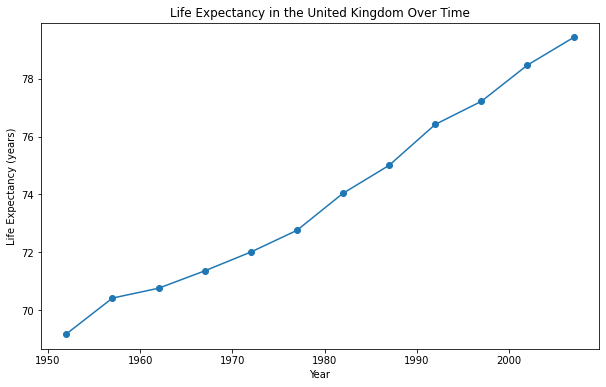

In [2]:
import matplotlib.pyplot as plt
uk_data = df[df['country'] == 'United Kingdom']
plt.figure(figsize=(10, 6))
plt.plot(uk_data['year'], uk_data['lifeExp'], marker='o')
plt.title('Life Expectancy in the United Kingdom Over Time')
plt.xlabel('Year')
plt.ylabel('Life Expectancy (years)')
plt.show()


3. Using Matplotlib, overlay on the same plot, life expectancy plots for the UK and Burkina Faso. Add a legend which indicates which colour represents each country.

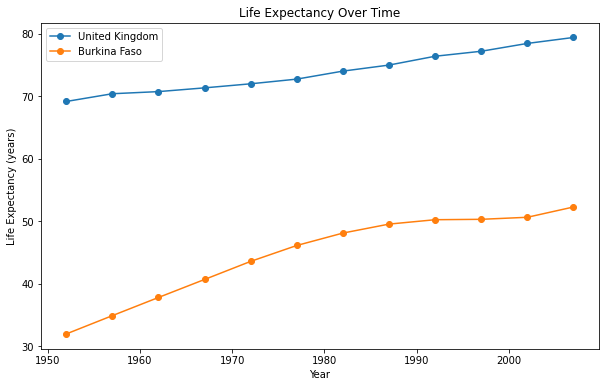

In [3]:
burk_data = df[df['country'] == 'Burkina Faso']
plt.figure(figsize=(10, 6))
plt.plot(uk_data['year'], uk_data['lifeExp'], marker='o', label='United Kingdom')
plt.plot(burk_data['year'], burk_data['lifeExp'], marker='o', label='Burkina Faso')
plt.title('Life Expectancy Over Time')
plt.xlabel('Year')
plt.ylabel('Life Expectancy (years)')
plt.legend()
plt.show()


4. Using `ggplot` function in `plotnine`, produce the same plot: life expectancy over time for both the UK and Burkina Faso. Make sure to first create a data frame that keeps only those rows for the UK and Burkina Faso.

In [39]:
!pip install plotnine
!pip install --upgrade pandas
!pip install --upgrade plotnine
from plotnine import ggplot, aes, geom_line, geom_point, labs, theme_minimal, geom_smooth, facet_wrap

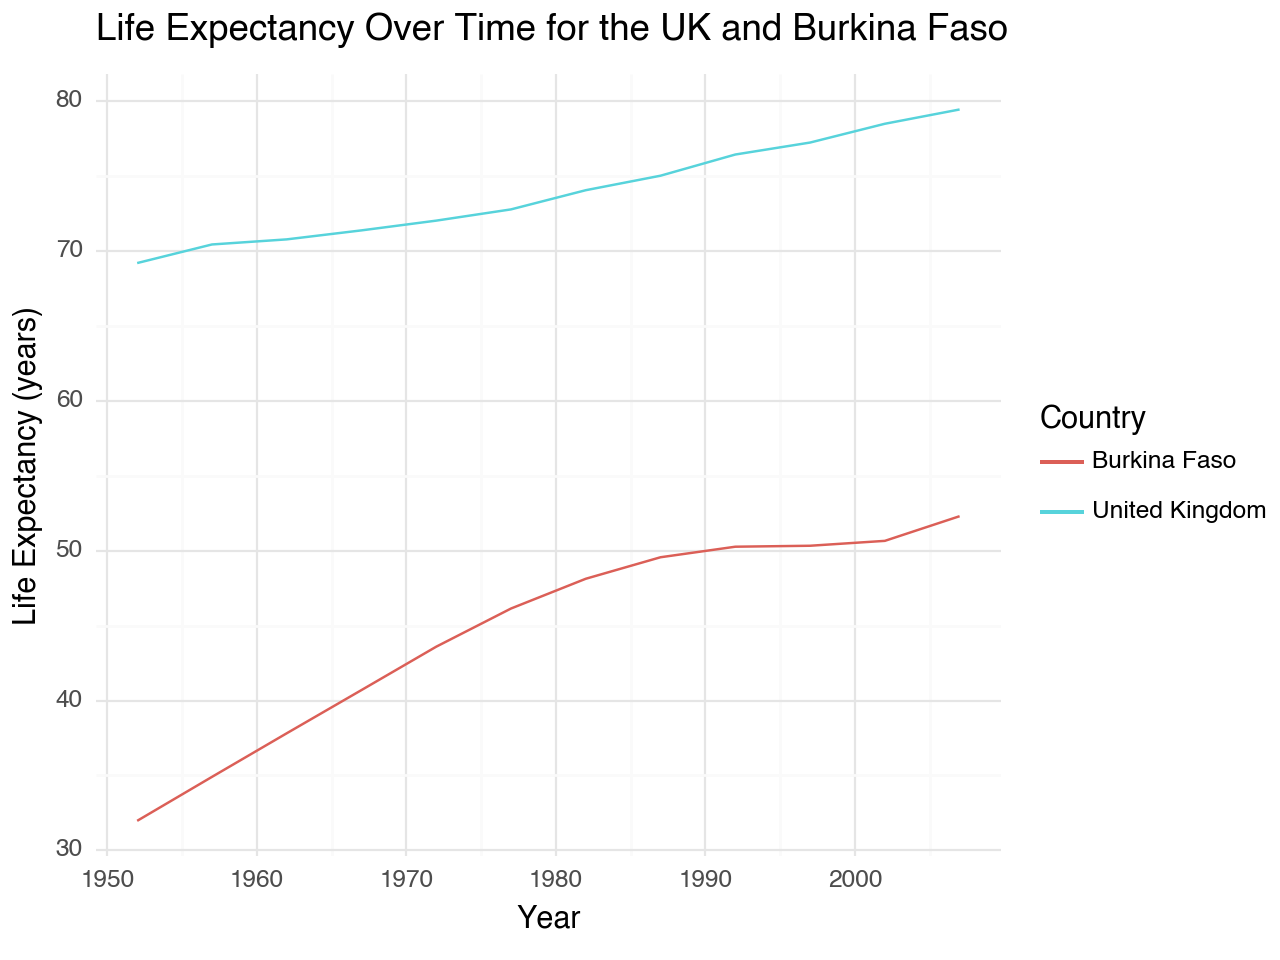

In [7]:
combined_data = df[df['country'].isin(['United Kingdom', 'Burkina Faso'])]
plot = (
    ggplot(combined_data, aes(x='year', y='lifeExp', color='country')) +
    geom_line() +
    labs(
        title='Life Expectancy Over Time for the UK and Burkina Faso',
        x='Year',
        y='Life Expectancy (years)',
        color='Country'
    ) +
    theme_minimal()
)
print(plot)


`(ggplot(df_uk_bf, aes(x='year', y='lifeExp', colour='country')) +
geom_line())`

5. Change `geom_line` to `geom_point` and examine how that changes the plot.

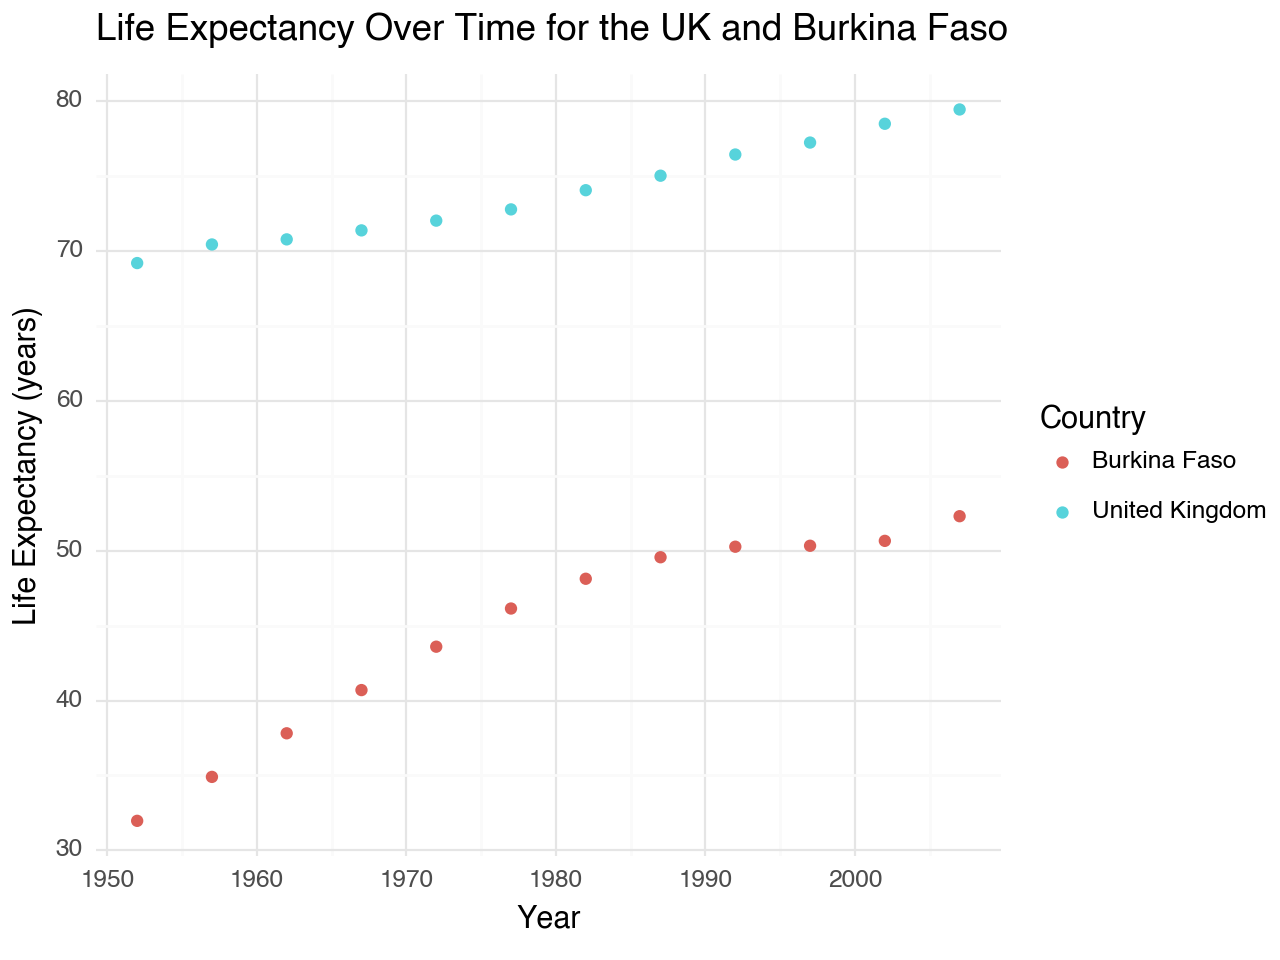

In [8]:
combined_data = df[df['country'].isin(['United Kingdom', 'Burkina Faso'])]
plot = (
    ggplot(combined_data, aes(x='year', y='lifeExp', color='country')) +
    geom_point() +
    labs(
        title='Life Expectancy Over Time for the UK and Burkina Faso',
        x='Year',
        y='Life Expectancy (years)',
        color='Country'
    ) +
    theme_minimal()
)
print(plot)

6. We can also layer geoms. Now include `+ geom_line()` in addition to `geom_point()`. What does this plot look like?

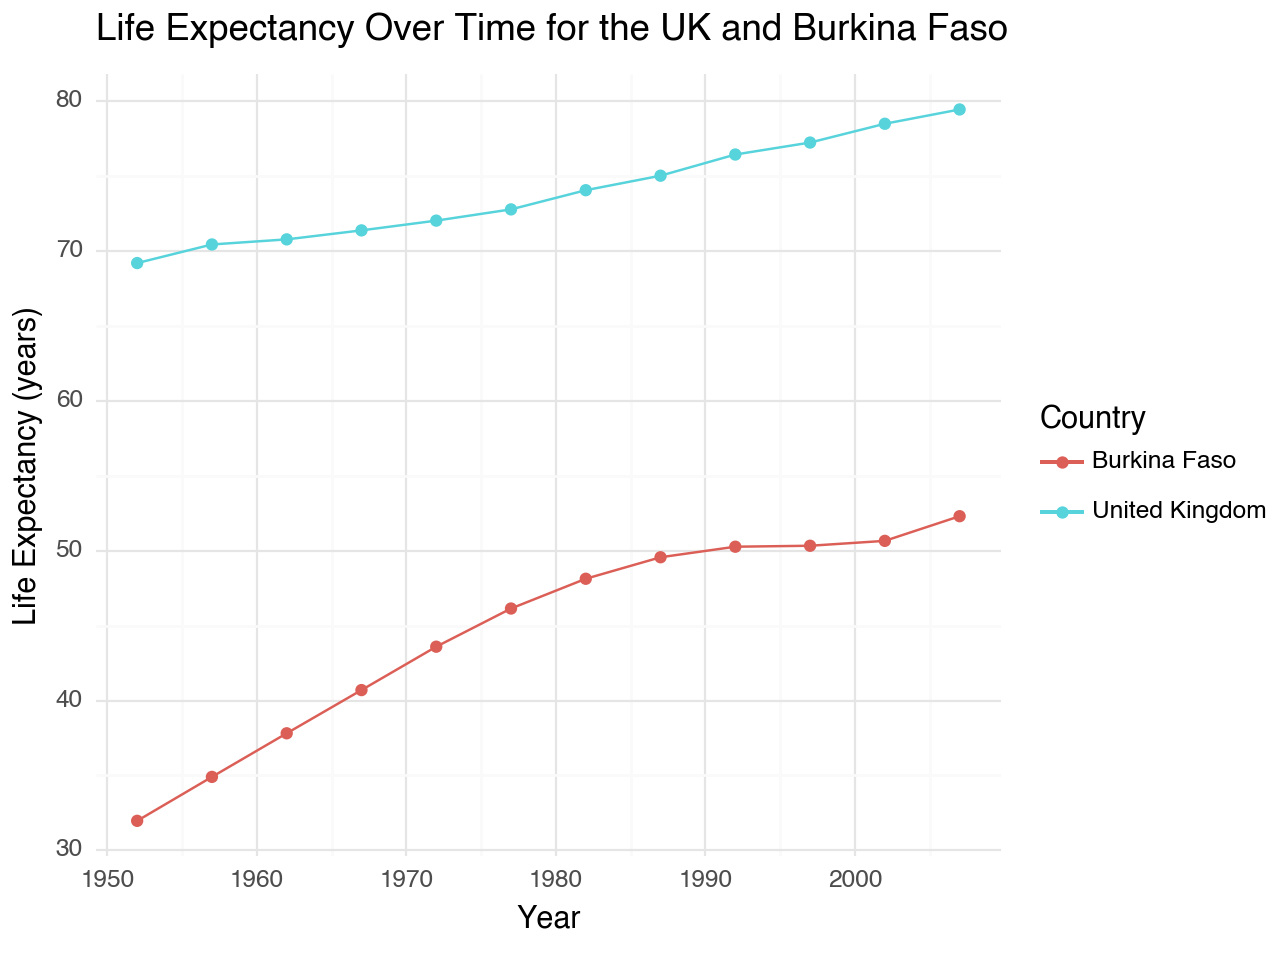

In [9]:
combined_data = df[df['country'].isin(['United Kingdom', 'Burkina Faso'])]
plot = (
    ggplot(combined_data, aes(x='year', y='lifeExp', color='country')) +
    geom_line() +
    geom_point() +
    labs(
        title='Life Expectancy Over Time for the UK and Burkina Faso',
        x='Year',
        y='Life Expectancy (years)',
        color='Country'
    ) +
    theme_minimal()
)
print(plot)

7. Suppose we want to add linear regression lines to data from each country. We can do this by adding + geom_smooth(method="lm") to the end of our plot command.

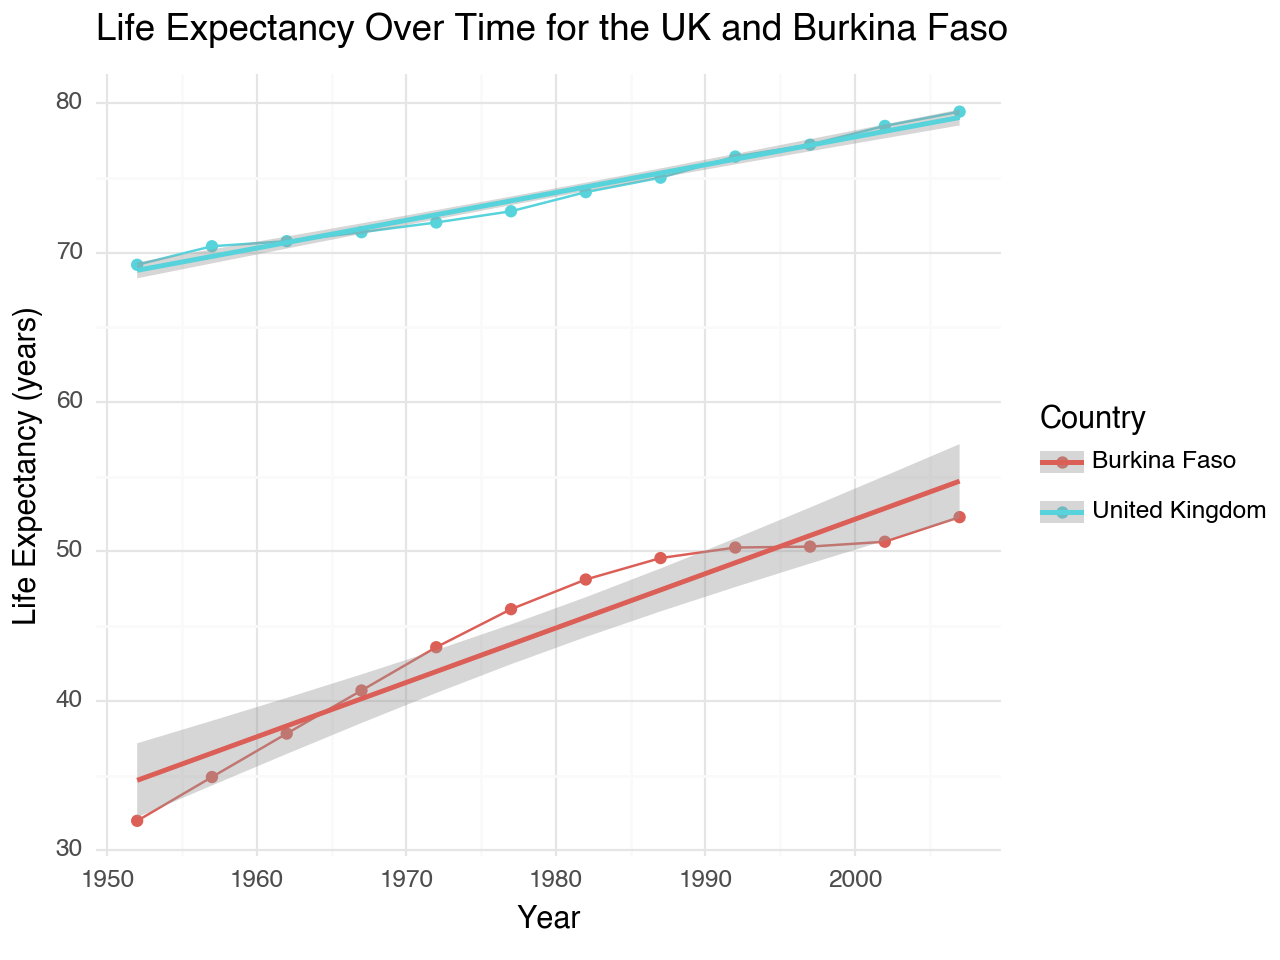

In [16]:

combined_data = df[df['country'].isin(['United Kingdom', 'Burkina Faso'])]
plot = (
    ggplot(combined_data, aes(x='year', y='lifeExp', color='country')) +
    geom_line() +
    geom_point() +
    geom_smooth(method="lm") +
    labs(
        title='Life Expectancy Over Time for the UK and Burkina Faso',
        x='Year',
        y='Life Expectancy (years)',
        color='Country'
    ) +
    theme_minimal()
)
print(plot)

8. We can remove the uncertainty intervals from the plots by changing `+ geom_smooth(method="lm")` to `+ geom_smooth(method="lm", se=False)`. Try this.

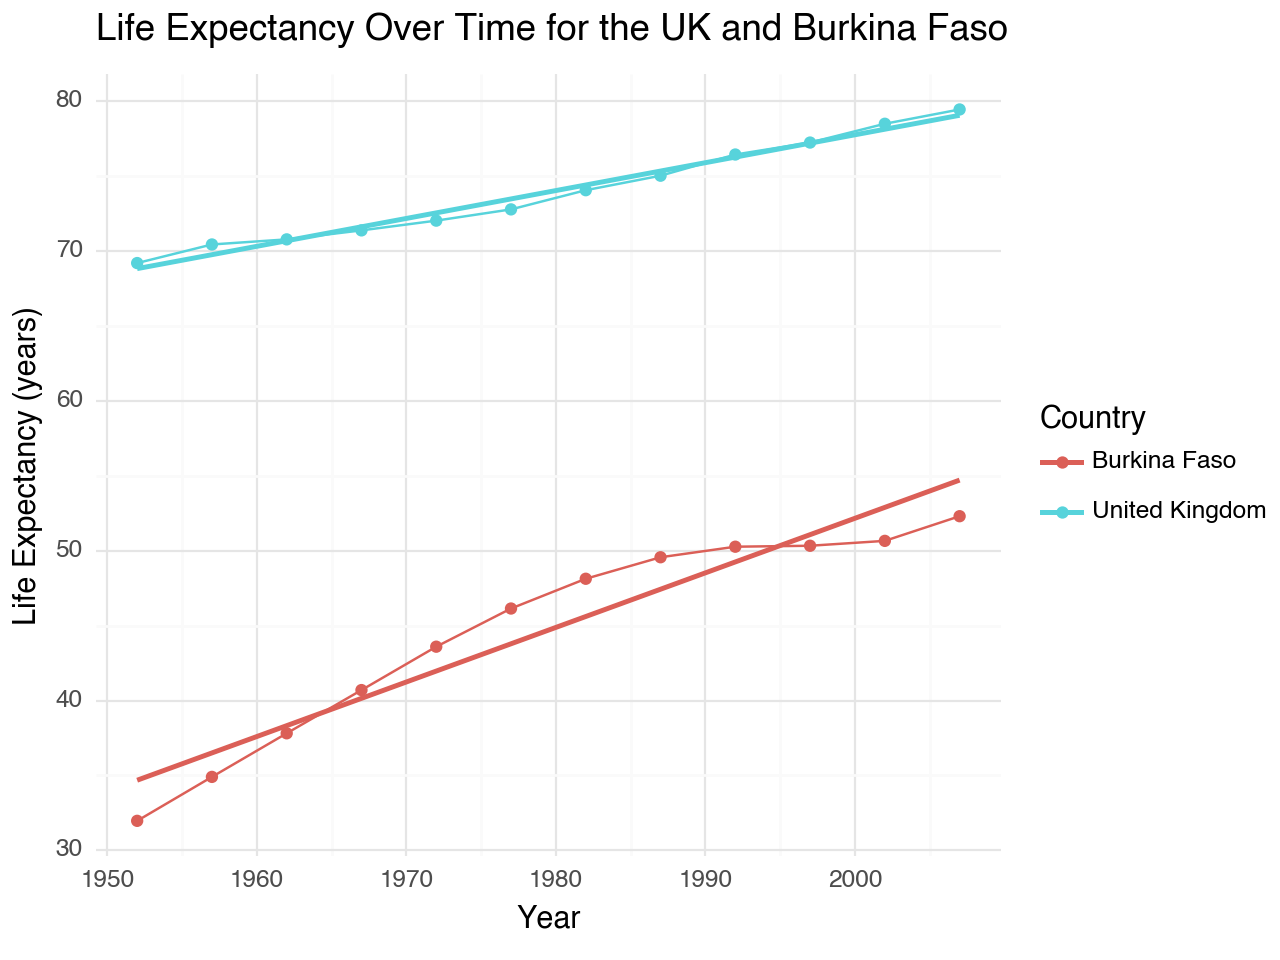

In [17]:
combined_data = df[df['country'].isin(['United Kingdom', 'Burkina Faso'])]
plot = (
    ggplot(combined_data, aes(x='year', y='lifeExp', color='country')) +
    geom_line() +
    geom_point() +
    geom_smooth(method="lm", se=False) +
    labs(
        title='Life Expectancy Over Time for the UK and Burkina Faso',
        x='Year',
        y='Life Expectancy (years)',
        color='Country'
    ) +
    theme_minimal()
)
print(plot)

9. Suppose instead of plotting two regression lines, we want a single regression line representing the trends across both countries. To do this, we can run the following code:

`(ggplot(df_uk_bf, aes(x='year', y='lifeExp')) +
geom_point(aes(colour='country')) +
geom_smooth(method="lm", se=False))`

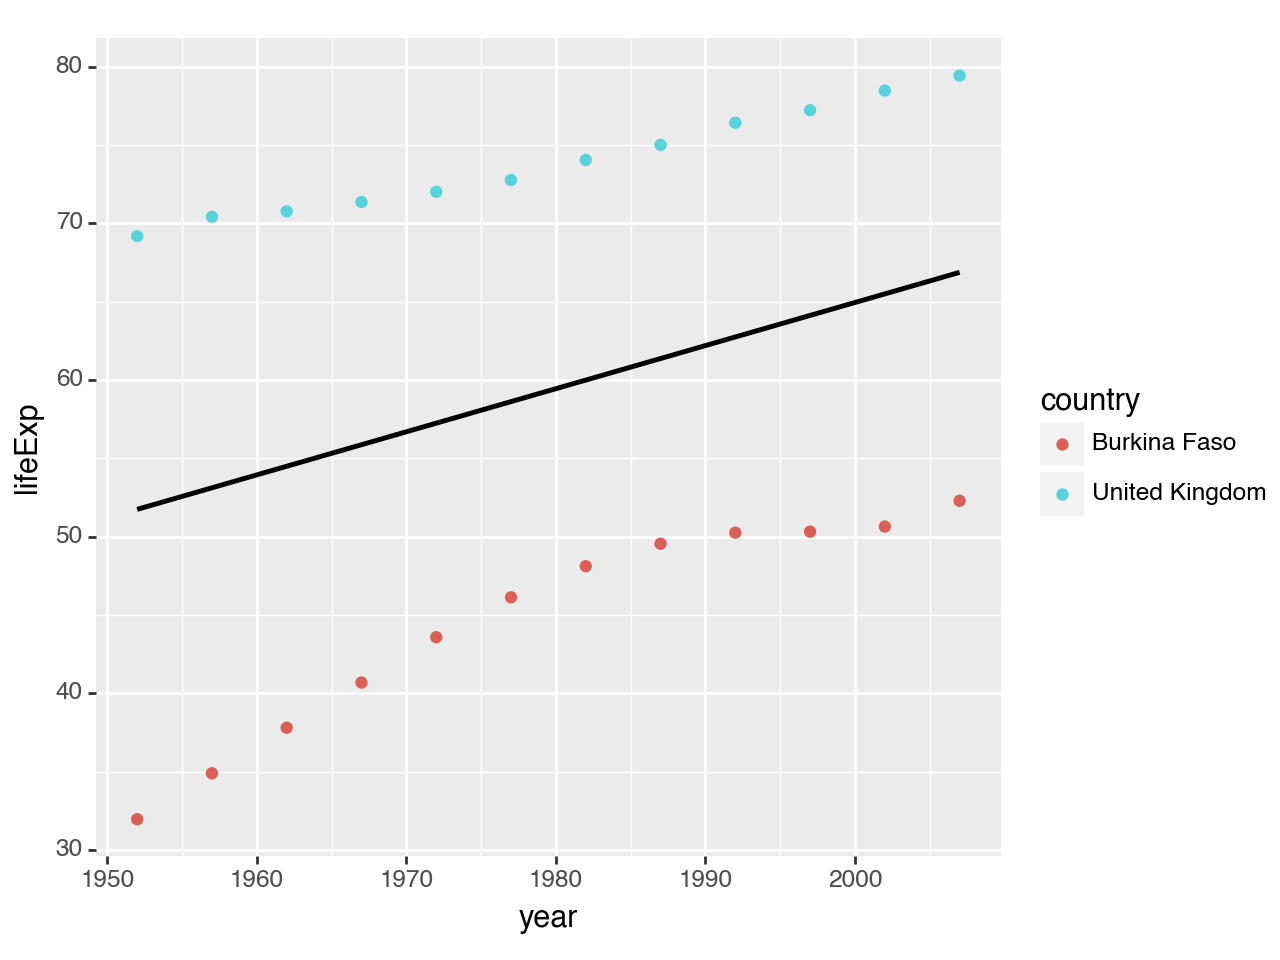

<Figure Size: (640 x 480)>

In [18]:
(ggplot(combined_data, aes(x='year', y='lifeExp')) +
geom_point(aes(colour='country')) +
geom_smooth(method="lm", se=False))

Why has the above code produced a single regression line?

10. Using `ggplot`, create a similar plot by considering all countries in the Americas.

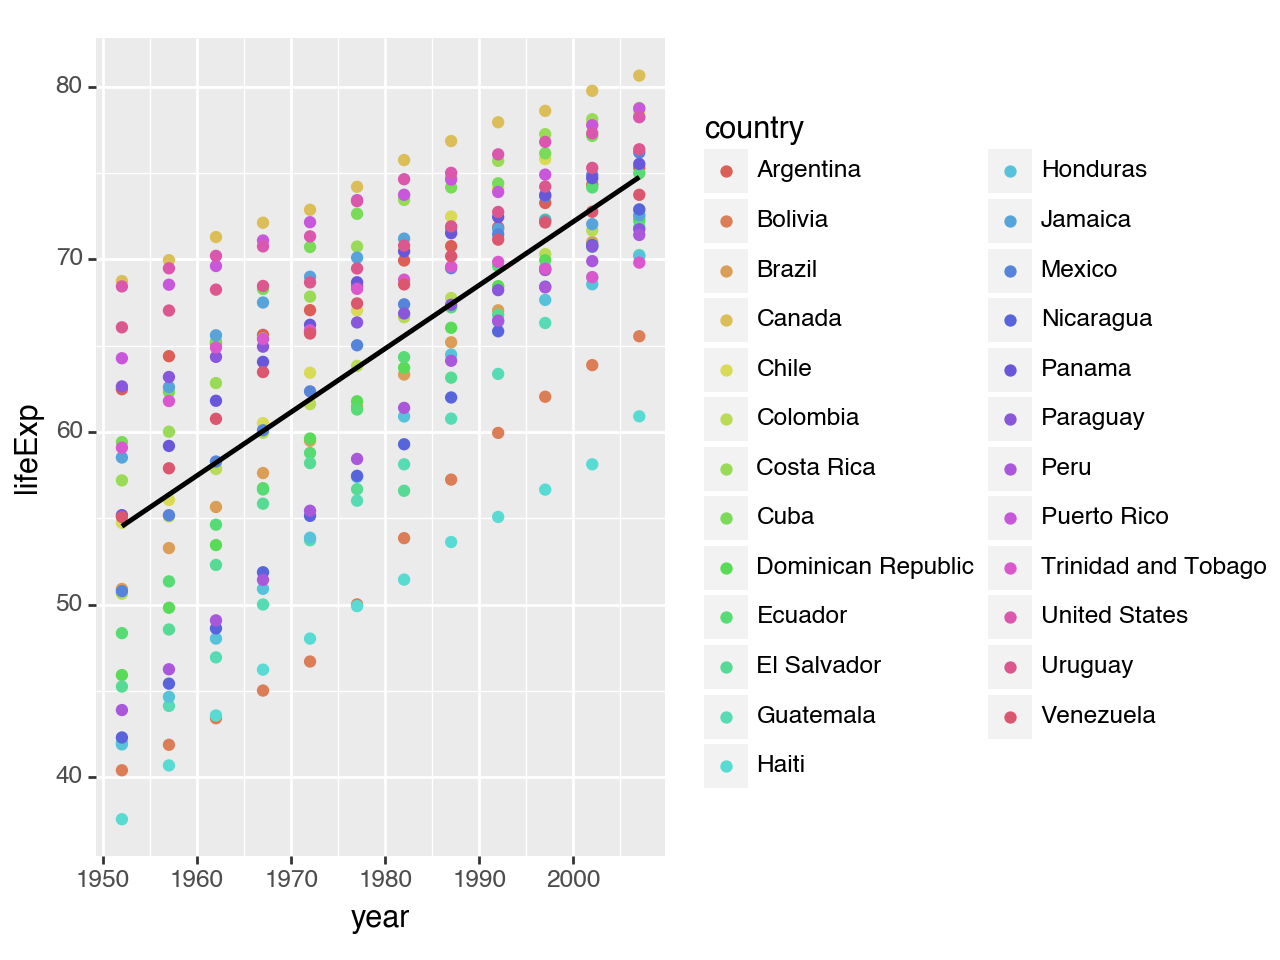

<Figure Size: (640 x 480)>

In [35]:
df_americas = df[df['continent'] == 'Americas']

(ggplot(df_americas, aes(x='year', y='lifeExp')) +
geom_point(aes(colour='country')) +
geom_smooth(method="lm", se=False))

11. We can also change our straight regression line into a curvy line using a locally weighted regression (known as a `loess` line). To do this, change from:

`geom_smooth(method="lm", se=False)` to `geom_smooth()`

What does this plot look like?

/Users/bengoodwin/opt/anaconda3/lib/python3.8/site-packages/plotnine/stats/smoothers.py:330: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.


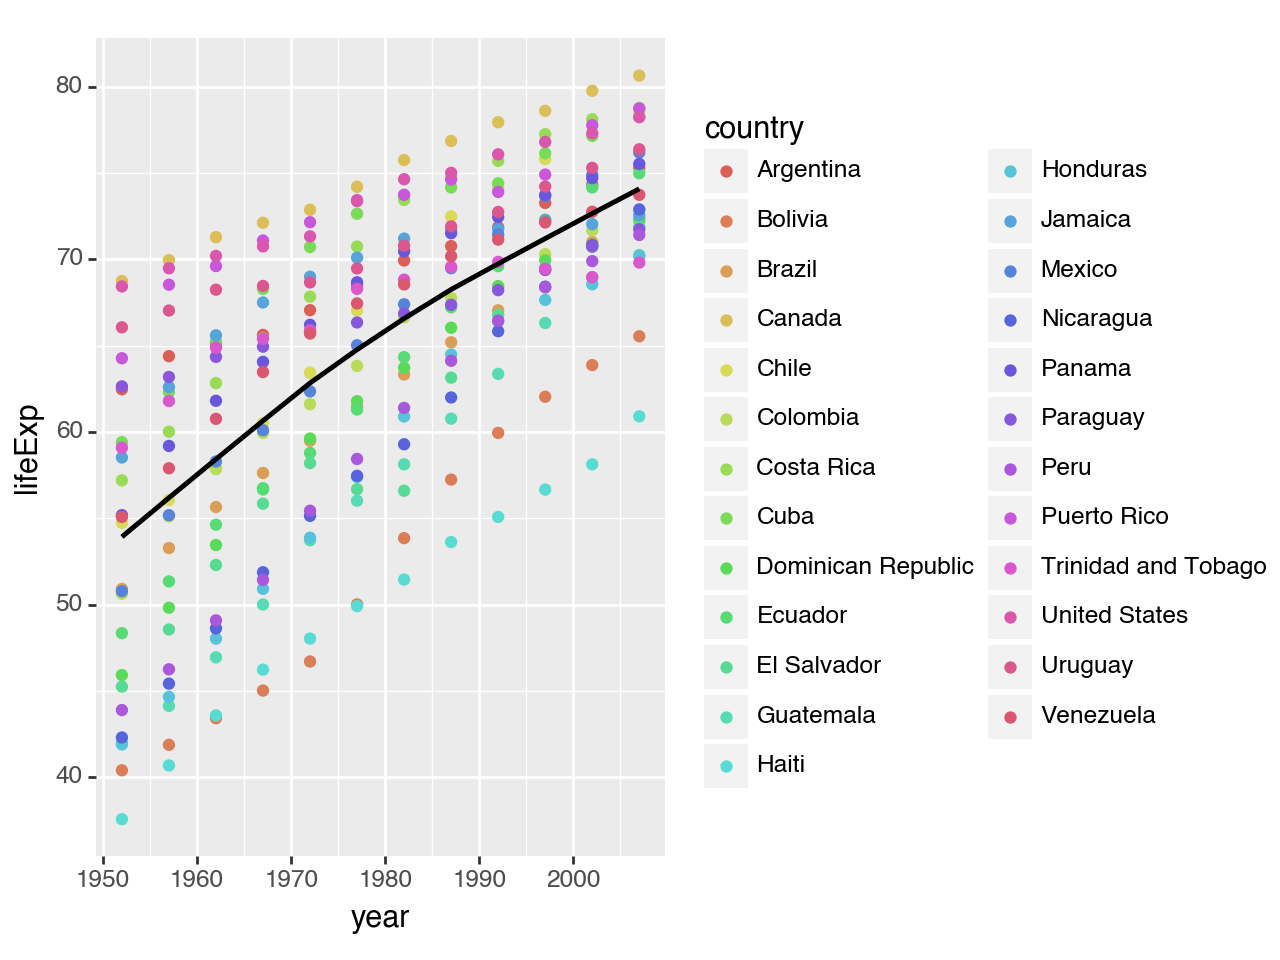

<Figure Size: (640 x 480)>

In [37]:
(ggplot(df_americas, aes(x='year', y='lifeExp')) +
geom_point(aes(colour='country')) +
geom_smooth())

12. We can also use `ggplot` to plot life expectancy over time for each continent in a given panel. To do so, run the following code:

`(ggplot(df, aes(x='year', y='lifeExp')) +
geom_point() +
facet_wrap('continent'))`

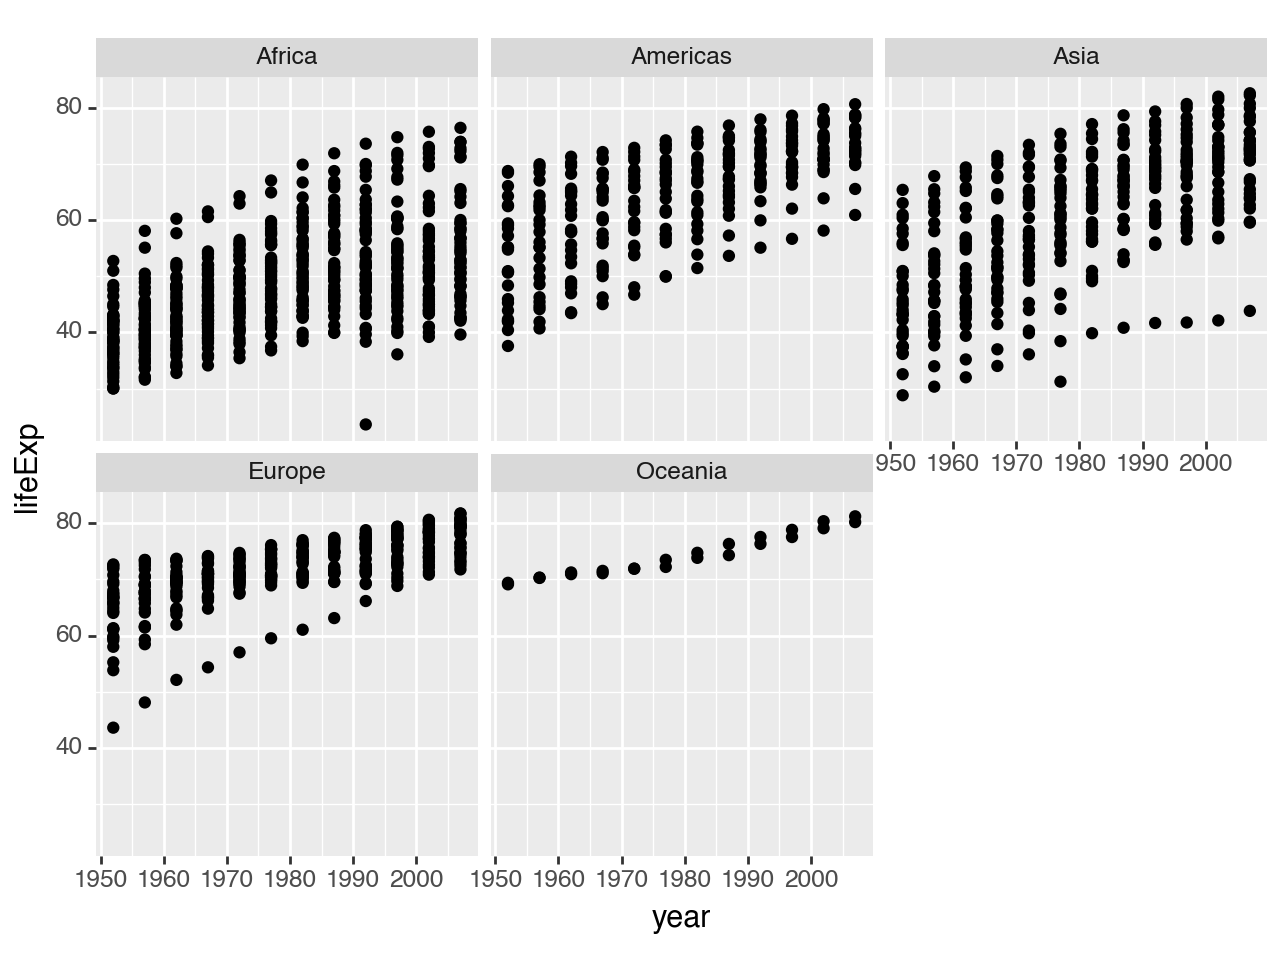

<Figure Size: (640 x 480)>

In [40]:
(ggplot(df, aes(x='year', y='lifeExp')) +
geom_point() +
facet_wrap('continent'))

Add a loess regression line to each of the panels above. Colour all of the regression lines in orange.

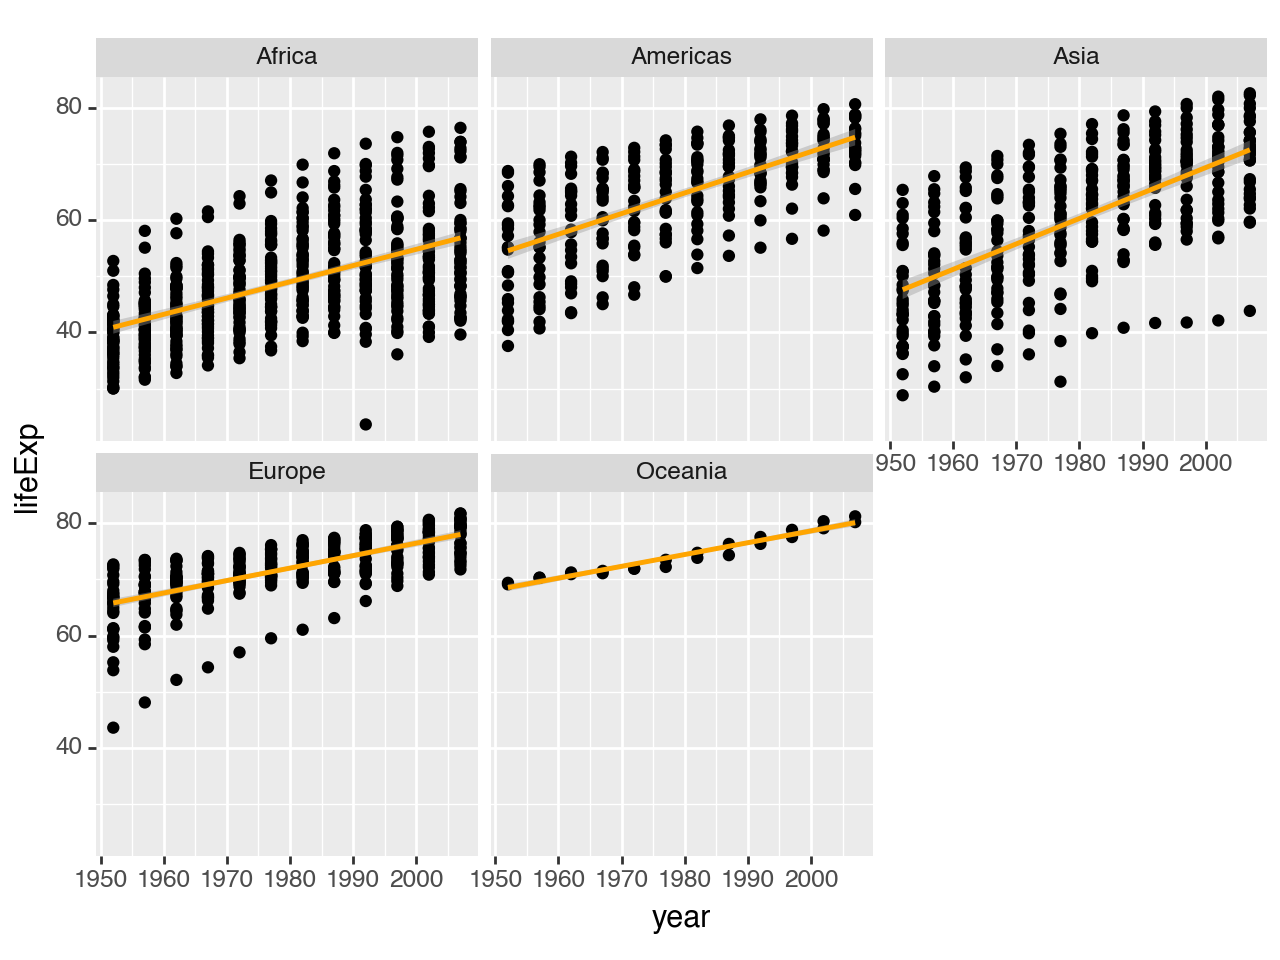

<Figure Size: (640 x 480)>

In [43]:
(ggplot(df, aes(x='year', y='lifeExp')) +
geom_point() +
geom_smooth(color="orange") +
facet_wrap('continent'))

### Advanced problem

Using visualisations, assess the following statement:

**"Increases in GDP (Gross Domestic Produce) per capita are associated with increases in life expectancy."**

In [54]:
df.head()
df["Log_gdpPercap"] = np.log(df["gdpPercap"])

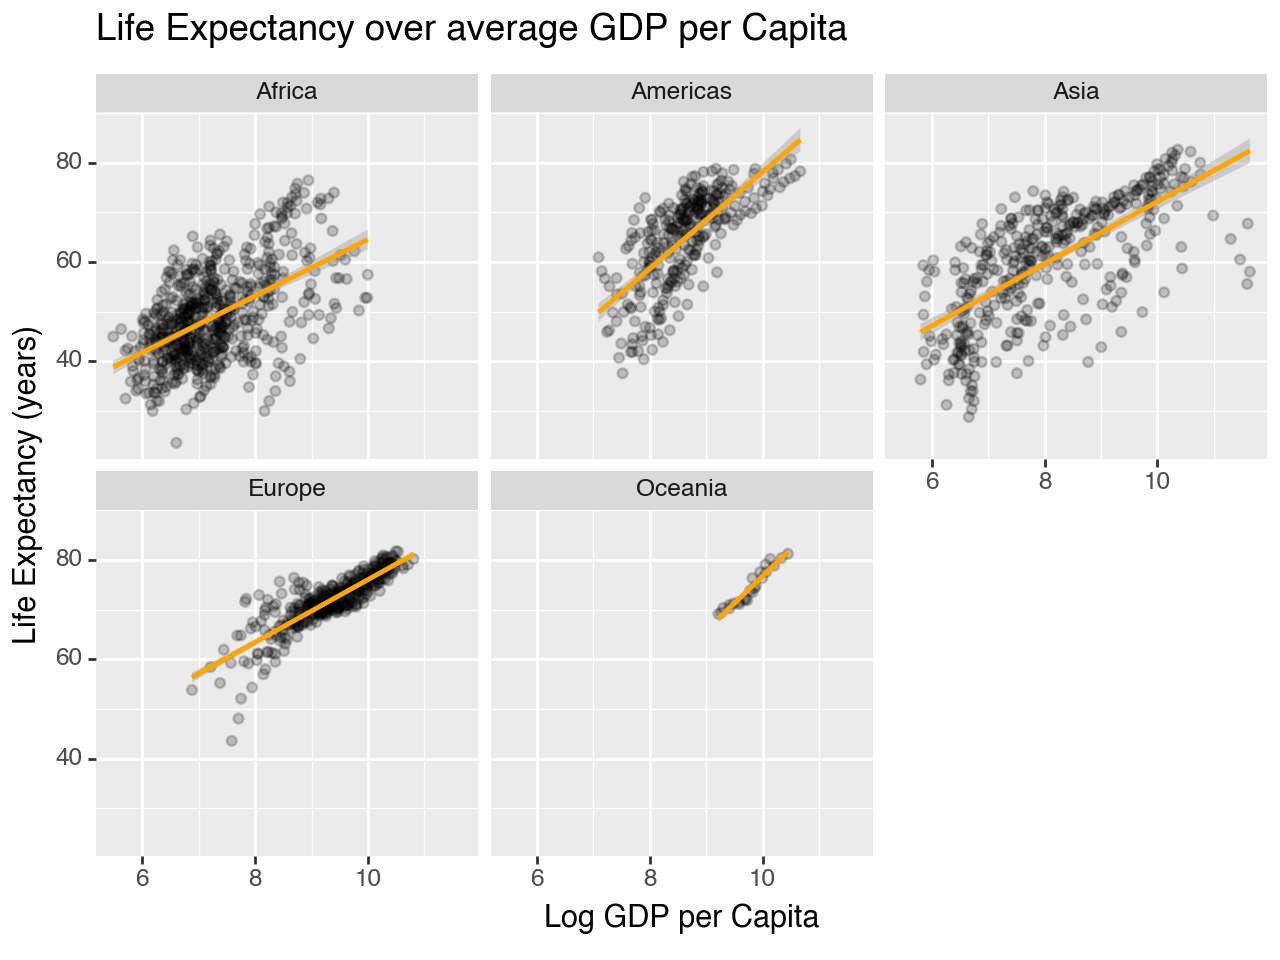

<Figure Size: (640 x 480)>

In [74]:
(ggplot(df, aes(x='Log_gdpPercap', y='lifeExp')) +
geom_point(alpha=0.2) +
geom_smooth(color="orange") +
labs(
    title='Life Expectancy over average GDP per Capita',
    x='Log GDP per Capita',
    y='Life Expectancy (years)',
) +
facet_wrap('continent'))

<ipython-input-63-6bca65f21e5e>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/Users/bengoodwin/opt/anaconda3/lib/python3.8/site-packages/plotnine/stats/smoothers.py:330: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.


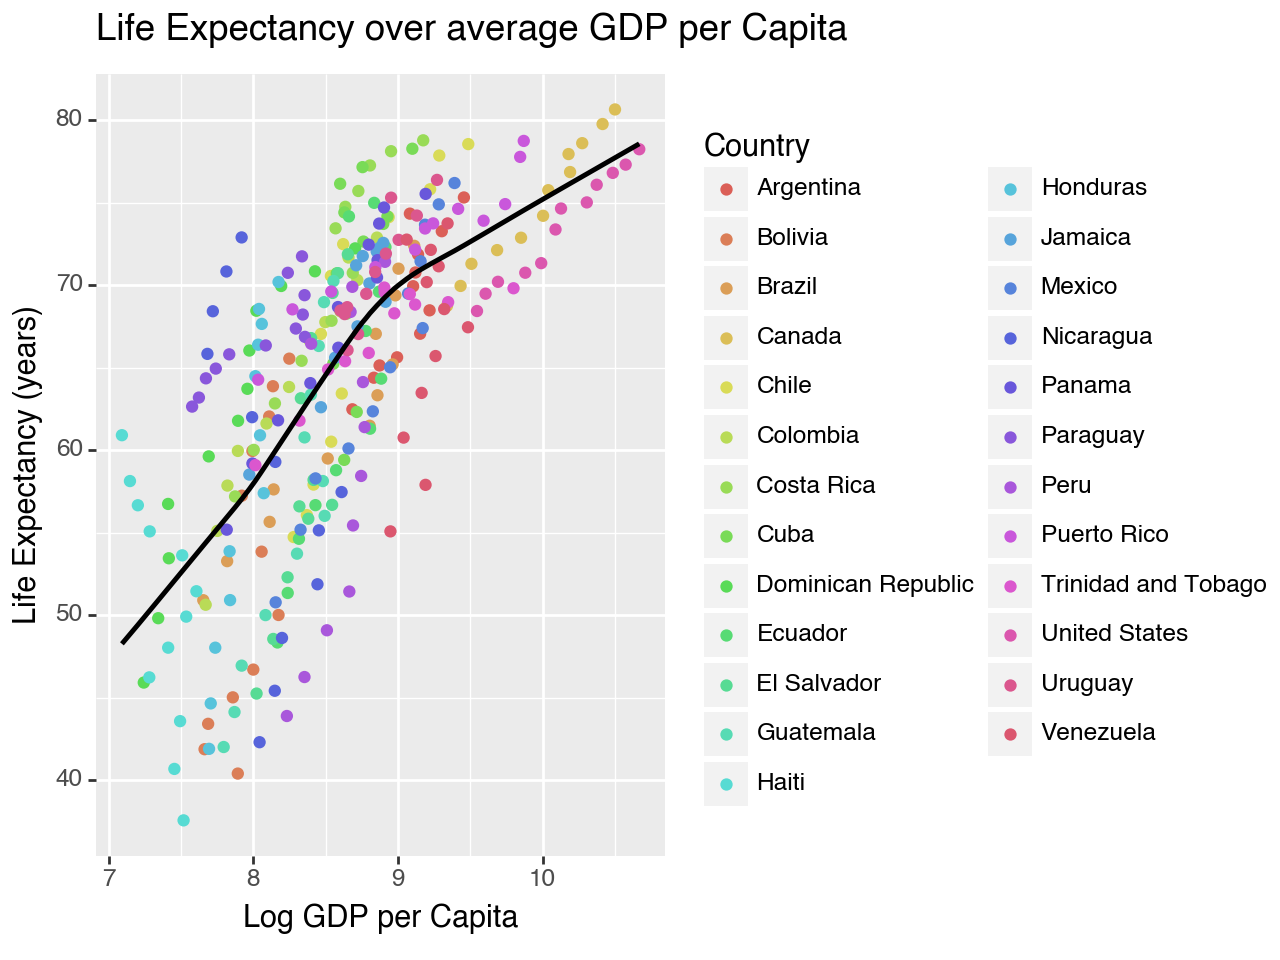

<Figure Size: (640 x 480)>

In [63]:
df_americas["Log_gdpPercap"] = np.log(df_americas["gdpPercap"])
(ggplot(df_americas, aes(x='Log_gdpPercap', y='lifeExp')) +
geom_point(aes(colour='country')) +
labs(
    title='Life Expectancy over average GDP per Capita',
    x='Log GDP per Capita',
    y='Life Expectancy (years)',
    color='Country'
) +
geom_smooth())

<ipython-input-64-aec9a9a82262>:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
/Users/bengoodwin/opt/anaconda3/lib/python3.8/site-packages/plotnine/stats/smoothers.py:330: PlotnineWarning: Confidence intervals are not yet implemented for lowess smoothings.


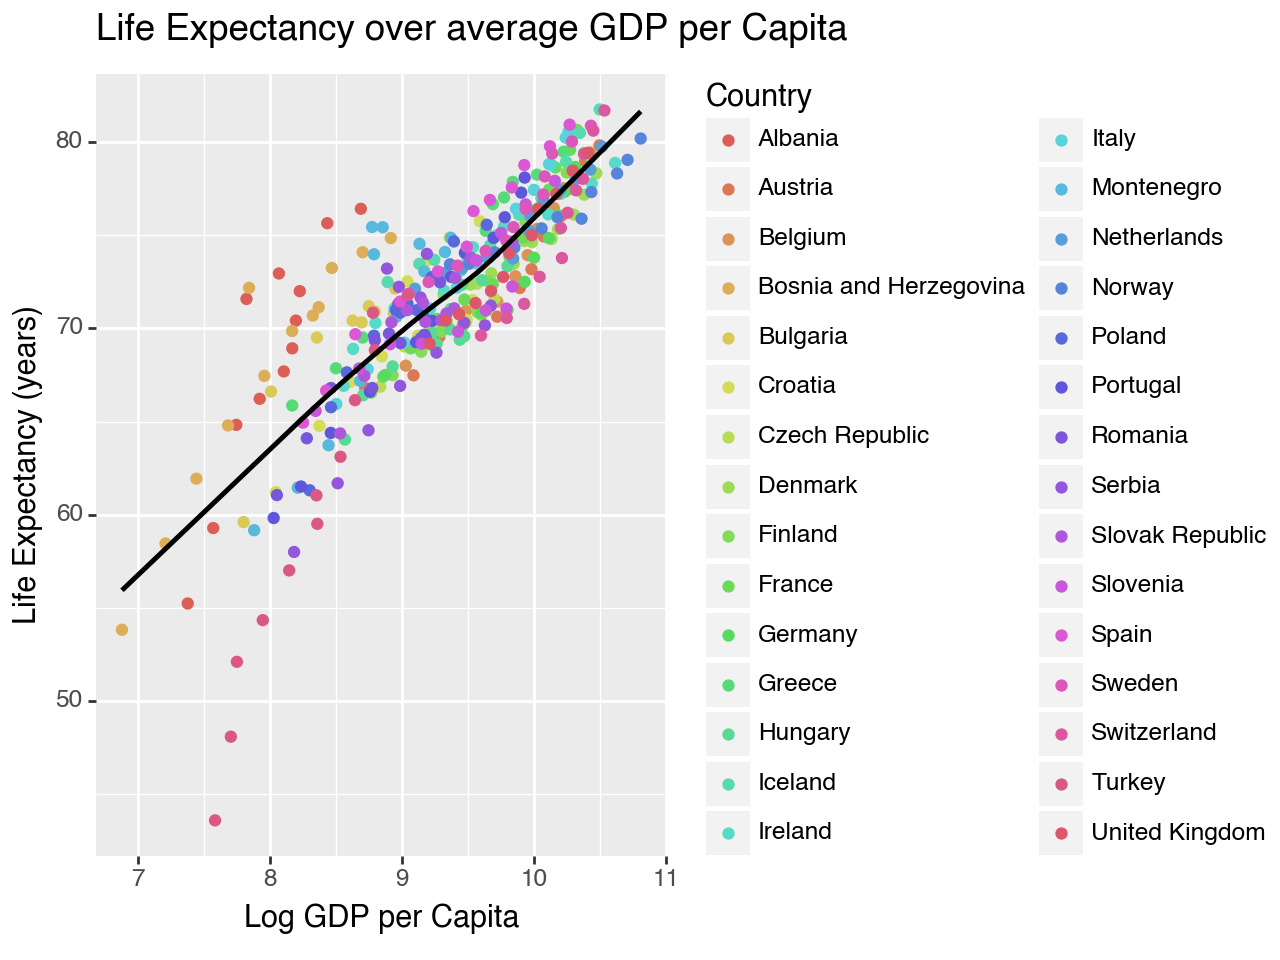

<Figure Size: (640 x 480)>

In [64]:
df_europe["Log_gdpPercap"] = np.log(df_europe["gdpPercap"])
(ggplot(df_europe, aes(x='Log_gdpPercap', y='lifeExp')) +
geom_point(aes(colour='country')) +
labs(
    title='Life Expectancy over average GDP per Capita',
    x='Log GDP per Capita',
    y='Life Expectancy (years)',
    color='Country'
) +
geom_smooth())